# Proyek Analisis Data: E-Commerce Public Dataset (Olist)
- **Nama:** Kartika Nur Savira
- **Email:** [Input Email]
- **ID Dicoding:** [Input Username]

## Menentukan Pertanyaan Bisnis

Seluruh analisis menggunakan data pesanan berstatus **delivered** pada periode **Januari 2017 – Agustus 2018** (data tahun 2016 serta September–Oktober 2018 tidak disertakan karena sangat sedikit dan tidak representatif).

Berikut adalah rumusan pertanyaan bisnis yang disusun dengan menerapkan metode **SMART Question** (*Specific, Measurable, Action-Oriented, Relevant, Time-bound*):

---

### **Pertanyaan 1: Performa Kategori Produk**
> **"Kategori produk apa saja yang menghasilkan total revenue tertinggi dan kuantitas unit terjual terbanyak, serta kategori mana yang paling rendah selama periode Januari 2017 – Agustus 2018?"**

- **Specific:** Fokus mengidentifikasi peringkat kategori produk unggulan (*top performers*) dan kategori terbawah (*underperformers*) berdasarkan dua parameter utama: total revenue (`price`) dan jumlah unit barang yang terjual (`order_item_id`).
- **Measurable:** Diukur secara konkret melalui agregasi nilai nominal penjualan (dalam mata uang Real Brasil / R$) dan kuantitas unit barang yang terjual.
- **Action-Oriented:** Memberikan acuan bagi tim *merchandising* dan operasional untuk memprioritaskan alokasi stok gudang, kampanye promosi, dan penataan *bundling* produk laris, serta mengevaluasi kelayakan retensi kategori dengan performa terendah.
- **Relevant:** Optimalisasi bauran produk berhubungan langsung dengan efisiensi modal kerja gudang dan pertumbuhan pendapatan utama platform.
- **Time-bound:** Dibatasi secara eksplisit pada rentang waktu pesanan terselesaikan (*delivered*) sepanjang Januari 2017 hingga Agustus 2018.

---

### **Pertanyaan 2: Logistik & Kepuasan Pelanggan**
> **"Seberapa besar penurunan rata-rata review score dan kenaikan persentase review negatif (skor 1–2) pada pesanan yang terlambat dibandingkan pesanan yang tiba tepat waktu selama periode Januari 2017 – Agustus 2018?"**

- **Specific:** Menganalisis korelasi langsung antara keterlambatan pengiriman (`delay_days > 0`) terhadap penurunan kepuasan konsumen yang tercermin pada skor ulasan (*review score*).
- **Measurable:** Dihitung dari selisih rata-rata rating (skala 1–5) serta persentase pesanan yang mendapatkan rating buruk (*negative review rate*, skor 1–2) pada kelompok keterlambatan (tepat waktu, telat 1–3 hari, 4–7 hari, dan >7 hari).
- **Action-Oriented:** Menentukan batas toleransi keterlambatan logistik, memperketat Service Level Agreement (SLA) pengiriman, dan merancang SOP kompensasi proaktif (voucher/diskon) sebelum pelanggan menuliskan ulasan negatif.
- **Relevant:** Ulasan pembeli berdampak langsung pada retensi konsumen, reputasi merchant, dan tingkat konversi calon pembeli baru.
- **Time-bound:** Berlaku khusus pada transaksi pesanan *delivered* yang memiliki catatan tanggal ulasan pada periode Januari 2017 hingga Agustus 2018.

---

### **Pertanyaan 3: Distribusi Geografis & Kendala Logistik Regional**
> **"Negara bagian (state) mana yang menyumbang jumlah pelanggan dan revenue terbesar, serta di state mana performa pengiriman paling lambat dan persentase keterlambatan paling tinggi selama periode Januari 2017 – Agustus 2018?"**

- **Specific:** Memetakan konsentrasi pasar konsumen terbesar di Brasil sekaligus mengidentifikasi titik rawan keterlambatan logistik berdasarkan letak geografis negara bagian (*customer_state*).
- **Measurable:** Terukur melalui akumulasi nilai revenue (R$), jumlah pelanggan unik, rata-rata durasi kirim (*delivery duration* dalam hari), dan persentase pesanan terlambat (%).
- **Action-Oriented:** Menjadi dasar pengambilan keputusan untuk ekspansi gudang regional (*fulfillment center* / *regional hub*), negosiasi tarif ekspedisi di rute rawan, atau penambahan mitra kurir lokal di wilayah bermasalah.
- **Relevant:** Mempersempit kesenjangan kualitas layanan logistik antardaerah guna meningkatkan kepuasan pelanggan secara nasional.
- **Time-bound:** Menggunakan data riwayat pesanan delivered sepanjang periode Januari 2017 hingga Agustus 2018.


## Import Semua Packages/Library yang Digunakan

In [ ]:
import unicodedata
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd  
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.options.display.float_format = '{:,.2f}'.format

## Data Wrangling

### Gathering Data

#### Load seluruh dataset

In [2]:
path = 'data/'

customers_df = pd.read_csv(path + 'customers_dataset.csv')
geolocation_df = pd.read_csv(path + 'geolocation_dataset.csv')
order_items_df = pd.read_csv(path + 'order_items_dataset.csv')
order_payments_df = pd.read_csv(path + 'order_payments_dataset.csv')
order_reviews_df = pd.read_csv(path + 'order_reviews_dataset.csv')
orders_df = pd.read_csv(
    path + 'orders_dataset.csv',
    parse_dates=['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
                 'order_delivered_customer_date', 'order_estimated_delivery_date'])
products_df = pd.read_csv(path + 'products_dataset.csv')
category_df = pd.read_csv(path + 'product_category_name_translation.csv')
sellers_df = pd.read_csv(path + 'sellers_dataset.csv')

datasets = {
    'customers': customers_df, 'geolocation': geolocation_df, 'order_items': order_items_df,
    'order_payments': order_payments_df, 'order_reviews': order_reviews_df, 'orders': orders_df,
    'products': products_df, 'category_translation': category_df, 'sellers': sellers_df,
}
pd.DataFrame({k: v.shape for k, v in datasets.items()}, index=['jumlah_baris', 'jumlah_kolom']).T

,jumlah_baris,jumlah_kolom
customers,99441,5
geolocation,1000163,5
order_items,112650,7
order_payments,103886,5
order_reviews,99224,7
orders,99441,8
products,32951,9
category_translation,71,2
sellers,3095,4


In [3]:
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


**Insight:**
- Dataset terdiri dari 9 file CSV. Tabel `orders` (99.441 pesanan) menjadi pusat relasi ke `customers`, `order_items`, `order_reviews`, dan `order_payments`; `order_items` terhubung ke `products` dan `sellers`.
- `geolocation` adalah tabel terbesar (±1 juta baris) karena satu zip code punya banyak titik koordinat.

### Assessing Data

#### Identifying missing value

In [4]:
for name, df in datasets.items():
    miss = df.isna().sum()
    miss = miss[miss > 0]
    if len(miss):
        print(f'== {name}')
        print(miss.to_frame('jumlah_missing').assign(persen=lambda x: (x.jumlah_missing / len(df) * 100).round(2)), '\n')

== order_reviews
                        jumlah_missing  persen
review_comment_title             87656   88.34
review_comment_message           58247   58.70 

== orders
                               jumlah_missing  persen
order_approved_at                         160    0.16
order_delivered_carrier_date             1783    1.79
order_delivered_customer_date            2965    2.98 

== products
                            jumlah_missing  persen
product_category_name                  610    1.85
product_name_lenght                    610    1.85
product_description_lenght             610    1.85
product_photos_qty                     610    1.85
product_weight_g                         2    0.01
product_length_cm                        2    0.01
product_height_cm                        2    0.01
product_width_cm                         2    0.01 



In [5]:
# Apakah missing value pada tanggal pengiriman wajar? Cek per status pesanan
orders_df.groupby('order_status')[['order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date']] \
    .agg(lambda s: s.isna().sum())

,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
order_status,,,
approved,0,2,2
canceled,141,550,619
created,5,5,5
delivered,14,2,8
invoiced,0,314,314
processing,0,301,301
shipped,0,0,1107
unavailable,0,609,609


#### Identifying duplicate data

In [6]:
for name, df in datasets.items():
    print(f'{name:22s} baris duplikat: {df.duplicated().sum()}')

print('\norder_id yang punya lebih dari satu review:', order_reviews_df['order_id'].duplicated().sum())

customers              baris duplikat: 0
geolocation            baris duplikat: 261831
order_items            baris duplikat: 0
order_payments         baris duplikat: 0
order_reviews          baris duplikat: 0
orders                 baris duplikat: 0
products               baris duplikat: 0
category_translation   baris duplikat: 0
sellers                baris duplikat: 0

order_id yang punya lebih dari satu review: 551


#### Identifying inconsistent value

In [7]:
# 1) Kategori produk yang tidak punya terjemahan Inggris
missing_translation = set(products_df['product_category_name'].dropna()) - set(category_df['product_category_name'])
print('Kategori tanpa terjemahan:', missing_translation)

# 2) Penulisan nama kota di geolocation mengandung aksen/karakter khusus, sedangkan customers tidak
print('\nNama kota geolocation dengan karakter non-huruf-kecil-ASCII:',
      geolocation_df['geolocation_city'].str.contains(r'[^a-z \-\']').sum())
print(geolocation_df.loc[geolocation_df['geolocation_city'].str.contains(r'[^a-z \-\']'), 'geolocation_city'].drop_duplicates().head(8).tolist())

Kategori tanpa terjemahan: {'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}

Nama kota geolocation dengan karakter non-huruf-kecil-ASCII: 73463
['são paulo', 'jundiaí', 'taboão da serra', 'sãopaulo', 'sa£o paulo', 'carapicuíba', 'santana de parnaíba', 'são lourenço da serra']


#### Identifying invalid value & outlier

In [8]:
# 1) Koordinat di luar wilayah Brasil (lat 5.3 s/d -34, lng -34 s/d -74)
out_brazil = geolocation_df[(geolocation_df['geolocation_lat'] > 5.3) | (geolocation_df['geolocation_lat'] < -34) |
                            (geolocation_df['geolocation_lng'] > -34) | (geolocation_df['geolocation_lng'] < -74)]
print('Koordinat di luar Brasil:', len(out_brazil))

# 2) Outlier harga produk (metode IQR)
q1, q3 = order_items_df['price'].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f'Batas atas outlier harga: {upper:,.2f} | jumlah outlier: {(order_items_df.price > upper).sum()} '
      f'({(order_items_df.price > upper).mean() * 100:.1f}%)')
print(order_items_df['price'].describe())

# 3) Pesanan delivered tetapi tanggal diterima pelanggan kosong
bad_delivered = orders_df[(orders_df['order_status'] == 'delivered') & orders_df['order_delivered_customer_date'].isna()]
print('\nPesanan delivered tanpa tanggal diterima:', len(bad_delivered))

Koordinat di luar Brasil: 42
Batas atas outlier harga: 277.40 | jumlah outlier: 8427 (7.5%)
count   112,650.00
mean        120.65
std         183.63
min           0.85
25%          39.90
50%          74.99
75%         134.90
max       6,735.00
Name: price, dtype: float64

Pesanan delivered tanpa tanggal diterima: 8


**Steps to Take:**
- **Missing value:** kolom tanggal pengiriman yang kosong pada status selain `delivered` wajar (pesanan belum/tidak sampai), sehingga analisis dibatasi pada pesanan `delivered`. Pesanan `delivered` tanpa tanggal diterima (invalid) dihapus. Kategori produk yang kosong diisi `unknown`.
- **Duplicate data:** hapus baris duplikat pada `geolocation`, lalu agregasi per `zip_code_prefix`. Review ganda pada satu `order_id` diagregasi menjadi rata-rata skor per pesanan agar tidak menggandakan baris saat merge.
- **Inconsistent value:** tambahkan terjemahan manual untuk 2 kategori yang belum ada, dan normalisasi nama kota geolocation (hilangkan aksen).
- **Invalid value:** hapus koordinat di luar wilayah Brasil.
- **Outlier:** harga outlier merupakan produk mahal yang wajar (bukan kesalahan input), sehingga **dipertahankan** dan ditangani dengan memakai median/agregasi yang tepat saat analisis.

**Insight:**
- Missing value pada tanggal pengiriman di `orders` sebagian besar wajar karena status pesanan belum `delivered` (dibatalkan, diproses, dikirim), kecuali 8 pesanan `delivered` yang tidak punya tanggal diterima.
- `geolocation` punya 261.831 baris duplikat, 551 `order_id` memiliki lebih dari satu review, dan 610 produk tidak punya kategori.
- Ada inkonsistensi penulisan (aksen dan salah encoding seperti `são paulo`, `sa£o paulo`), 2 kategori tanpa terjemahan, 42 koordinat di luar Brasil, dan 7,5% harga tergolong outlier namun masih wajar sebagai produk mahal.

### Cleaning Data

#### Fixing missing value & invalid value pada orders

In [9]:
orders_clean = orders_df[orders_df['order_status'] == 'delivered'].copy()
orders_clean = orders_clean.dropna(subset=['order_delivered_customer_date'])

# Batasi periode analisis: Januari 2017 - Agustus 2018
orders_clean = orders_clean[(orders_clean['order_purchase_timestamp'] >= '2017-01-01') &
                            (orders_clean['order_purchase_timestamp'] < '2018-09-01')]
print('Jumlah pesanan setelah dibersihkan:', len(orders_clean))
print('Missing value tersisa pada orders_clean:', orders_clean[['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']].isna().sum().sum())

Jumlah pesanan setelah dibersihkan: 96203
Missing value tersisa pada orders_clean: 0


#### Fixing missing value & inconsistent value pada products

In [10]:
products_clean = products_df.copy()
products_clean['product_category_name'] = products_clean['product_category_name'].fillna('unknown')

extra = pd.DataFrame({
    'product_category_name': ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos', 'unknown'],
    'product_category_name_english': ['pc_gamer', 'portable_kitchen_food_preparers', 'unknown']})
category_clean = pd.concat([category_df, extra], ignore_index=True)

products_clean = products_clean.merge(category_clean, on='product_category_name', how='left')
print('Kategori tanpa terjemahan setelah dibersihkan:', products_clean['product_category_name_english'].isna().sum())

Kategori tanpa terjemahan setelah dibersihkan: 0


#### Fixing duplicate data pada reviews

In [11]:
reviews_clean = (order_reviews_df.groupby('order_id', as_index=False)
                 .agg(review_score=('review_score', 'mean')))
print('order_id duplikat setelah agregasi:', reviews_clean['order_id'].duplicated().sum())

order_id duplikat setelah agregasi: 0


#### Fixing duplicate, invalid & inconsistent value pada geolocation

In [12]:
def normalize(text):
    return unicodedata.normalize('NFKD', text).encode('ascii', 'ignore').decode('ascii').lower().strip()

geo_clean = geolocation_df.drop_duplicates().copy()
geo_clean = geo_clean[(geo_clean['geolocation_lat'].between(-34, 5.3)) & (geo_clean['geolocation_lng'].between(-74, -34))]
geo_clean['geolocation_city'] = geo_clean['geolocation_city'].apply(normalize)

# satu titik koordinat per zip code prefix
geo_zip = (geo_clean.groupby('geolocation_zip_code_prefix', as_index=False)
           .agg(lat=('geolocation_lat', 'mean'), lng=('geolocation_lng', 'mean')))
print('Baris geolocation: sebelum', len(geolocation_df), '-> sesudah dibersihkan & diagregasi', len(geo_zip))

Baris geolocation: sebelum 1000163 -> sesudah dibersihkan & diagregasi 19010


#### Menggabungkan seluruh data (master dataframe tingkat item pesanan)

In [13]:
master_df = (order_items_df
             .merge(orders_clean[['order_id', 'customer_id', 'order_purchase_timestamp',
                                  'order_delivered_customer_date', 'order_estimated_delivery_date']], on='order_id', how='inner')
             .merge(products_clean[['product_id', 'product_category_name_english']], on='product_id', how='left')
             .merge(customers_df[['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_state']], on='customer_id', how='left')
             .merge(reviews_clean, on='order_id', how='left')
             .merge(geo_zip, left_on='customer_zip_code_prefix', right_on='geolocation_zip_code_prefix', how='left')
             .drop(columns='geolocation_zip_code_prefix'))

master_df = master_df.rename(columns={'product_category_name_english': 'category'})

# Fitur turunan
master_df['delivery_days'] = (master_df['order_delivered_customer_date'] - master_df['order_purchase_timestamp']).dt.total_seconds() / 86400
master_df['delay_days'] = (master_df['order_delivered_customer_date'] - master_df['order_estimated_delivery_date']).dt.total_seconds() / 86400
master_df['is_late'] = master_df['delay_days'] > 0
master_df['delay_group'] = pd.cut(master_df['delay_days'], bins=[-np.inf, 0, 3, 7, np.inf],
                                   labels=['Tepat waktu/lebih cepat', 'Telat 1-3 hari', 'Telat 4-7 hari', 'Telat >7 hari'])
master_df['order_month'] = master_df['order_purchase_timestamp'].dt.to_period('M').astype(str)

print(master_df.shape)
master_df.isna().sum()[lambda s: s > 0]

(109872, 23)


review_score    823
lat             289
lng             289
dtype: int64

**Insight:**
- Setelah dibersihkan dan difilter ke pesanan `delivered` periode Jan 2017 – Agu 2018, tersisa **96.203 pesanan** dari **93.096 pelanggan unik** dengan total revenue ±R$ 13,18 juta.
- Geolocation berkurang dari ±1 juta baris menjadi 19.010 titik (satu per zip code prefix) sehingga ringan dipakai untuk analisis geospasial.
- Master dataframe (109.872 baris item) siap dipakai untuk EDA dan dashboard.

## Exploratory Data Analysis (EDA)

### Explore ringkasan data

In [14]:
master_df[['price', 'freight_value', 'delivery_days', 'delay_days', 'review_score']].describe()

,price,freight_value,delivery_days,delay_days,review_score
count,"109,872.00","109,872.00","109,872.00","109,872.00","109,049.00"
mean,119.96,19.95,12.45,-11.26,4.08
std,182.35,15.70,9.43,10.06,1.35
min,0.85,0.00,0.53,-146.02,1.00
25%,39.90,13.08,6.72,-16.30,4.00
50%,74.90,16.26,10.18,-12.03,5.00
75%,134.04,21.15,15.50,-6.46,5.00
max,"6,735.00",409.68,209.63,188.98,5.00


In [15]:
print('Jumlah pesanan unik   :', master_df['order_id'].nunique())
print('Jumlah pelanggan unik :', master_df['customer_unique_id'].nunique())
print('Total revenue (price) : R$ {:,.0f}'.format(master_df['price'].sum()))
print('Periode               :', master_df['order_purchase_timestamp'].min().date(), 's/d', master_df['order_purchase_timestamp'].max().date())

Jumlah pesanan unik   : 96203
Jumlah pelanggan unik : 93096
Total revenue (price) : R$ 13,179,778
Periode               : 2017-01-05 s/d 2018-08-29


### Explore kategori produk (Pertanyaan 1)

In [16]:
category_summary = (master_df.groupby('category')
                    .agg(revenue=('price', 'sum'), unit_terjual=('order_item_id', 'count'), jumlah_order=('order_id', 'nunique'),
                         rata_rata_harga=('price', 'mean'))
                    .sort_values('revenue', ascending=False))
category_summary['persen_revenue'] = category_summary['revenue'] / category_summary['revenue'].sum() * 100
print('Jumlah kategori:', len(category_summary))
category_summary.head(10)

Jumlah kategori: 74


,revenue,unit_terjual,jumlah_order,rata_rata_harga,persen_revenue
category,,,,,
health_beauty,"1,229,557.50",9422,8610,130.50,9.33
watches_gifts,"1,163,187.91",5853,5489,198.73,8.83
bed_bath_table,"1,022,955.77",10945,9267,93.46,7.76
sports_leisure,"952,661.40",8413,7512,113.24,7.23
computers_accessories,"887,944.60",7631,6517,116.36,6.74
furniture_decor,"706,237.17",8095,6258,87.24,5.36
housewares,"614,341.62",6783,5734,90.57,4.66
cool_stuff,"609,158.00",3711,3552,164.15,4.62
auto,"577,721.09",4131,3801,139.85,4.38


In [17]:
category_summary.sort_values('revenue').head(10)

,revenue,unit_terjual,jumlah_order,rata_rata_harga,persen_revenue
category,,,,,
security_and_services,283.29,2,2,141.64,0.00
fashion_childrens_clothes,519.95,7,7,74.28,0.00
cds_dvds_musicals,730.00,14,12,52.14,0.01
home_comfort_2,760.27,30,24,25.34,0.01
flowers,"1,110.04",33,29,33.64,0.01
pc_gamer,"1,306.95",8,7,163.37,0.01
diapers_and_hygiene,"1,365.89",36,24,37.94,0.01
arts_and_craftmanship,"1,814.01",24,23,75.58,0.01
la_cuisine,"2,054.99",14,13,146.78,0.02


In [18]:
top5_share = category_summary['persen_revenue'].head(5).sum()
print(f'5 kategori teratas menyumbang {top5_share:.1f}% dari total revenue')
category_summary.sort_values('unit_terjual', ascending=False).head(5)[['unit_terjual', 'revenue']]

5 kategori teratas menyumbang 39.9% dari total revenue


,unit_terjual,revenue
category,,
bed_bath_table,10945,"1,022,955.77"
health_beauty,9422,"1,229,557.50"
sports_leisure,8413,"952,661.40"
furniture_decor,8095,"706,237.17"
computers_accessories,7631,"887,944.60"


### Explore keterlambatan pengiriman & review (Pertanyaan 2)

In [19]:
order_level = (master_df.drop_duplicates('order_id')[['order_id', 'customer_state', 'delivery_days', 'delay_days', 'is_late', 'delay_group', 'review_score']])
order_level['review_negatif'] = order_level['review_score'] <= 2

print('Persentase pesanan terlambat: {:.1f}%'.format(order_level['is_late'].mean() * 100))
delay_summary = (order_level.groupby('delay_group')
                 .agg(jumlah_order=('order_id', 'count'), rata_rata_review=('review_score', 'mean'),
                      persen_review_negatif=('review_negatif', lambda s: s.mean() * 100)))
delay_summary

Persentase pesanan terlambat: 8.1%


,jumlah_order,rata_rata_review,persen_review_negatif
delay_group,,,
Tepat waktu/lebih cepat,88381,4.30,9.12
Telat 1-3 hari,2660,3.77,18.91
Telat 4-7 hari,1819,2.32,59.70
Telat >7 hari,3343,1.73,76.13


In [20]:
late_summary = order_level.groupby('is_late').agg(rata_rata_review=('review_score', 'mean'),
                                                  persen_review_negatif=('review_negatif', lambda s: s.mean() * 100))
late_summary.index = ['Tepat waktu', 'Terlambat']
print(late_summary)
print('\nKorelasi delay_days vs review_score: {:.3f}'.format(order_level['delay_days'].corr(order_level['review_score'])))

             rata_rata_review  persen_review_negatif
Tepat waktu              4.30                   9.12
Terlambat                2.57                  52.85

Korelasi delay_days vs review_score: -0.270


### Explore state pelanggan (Pertanyaan 3)

In [21]:
order_value = master_df.groupby('order_id').agg(order_value=('price', 'sum'))
state_summary = (master_df.drop_duplicates('order_id')[['order_id', 'customer_unique_id', 'customer_state', 'delivery_days', 'is_late']]
                 .merge(order_value, on='order_id')
                 .groupby('customer_state')
                 .agg(pelanggan=('customer_unique_id', 'nunique'), jumlah_order=('order_id', 'count'), revenue=('order_value', 'sum'),
                      rata_rata_hari_kirim=('delivery_days', 'mean'), persen_terlambat=('is_late', lambda s: s.mean() * 100))
                 .sort_values('revenue', ascending=False))
state_summary['persen_revenue'] = state_summary['revenue'] / state_summary['revenue'].sum() * 100
state_summary['persen_pelanggan'] = state_summary['pelanggan'] / state_summary['pelanggan'].sum() * 100
state_summary.head(10)

,pelanggan,jumlah_order,revenue,rata_rata_hari_kirim,persen_terlambat,persen_revenue,persen_pelanggan
customer_state,,,,,,,
SP,39058,40399,"5,054,516.95",8.74,5.90,38.35,41.94
RJ,11879,12310,"1,751,433.85",15.30,13.52,13.29,12.75
MG,10969,11319,"1,548,206.88",11.98,5.63,11.75,11.78
RS,5150,5327,"726,194.92",15.29,7.17,5.51,5.53
PR,4750,4903,"664,048.00",11.97,5.02,5.04,5.10
SC,3441,3537,"504,774.07",14.95,9.78,3.83,3.69
BA,3155,3253,"493,339.26",19.33,14.05,3.74,3.39
DF,2013,2074,"295,454.64",12.94,7.09,2.24,2.16
GO,1889,1950,"281,932.21",15.61,8.21,2.14,2.03


In [22]:
state_summary.sort_values('rata_rata_hari_kirim', ascending=False).head(5)[['pelanggan', 'rata_rata_hari_kirim', 'persen_terlambat']]

,pelanggan,rata_rata_hari_kirim,persen_terlambat
customer_state,,,
RR,39,29.91,12.50
AP,66,27.19,4.48
AM,140,26.43,4.14
AL,386,24.52,23.99
PA,918,23.76,12.42


In [23]:
state_summary.sort_values('persen_terlambat', ascending=False).head(5)[['pelanggan', 'rata_rata_hari_kirim', 'persen_terlambat']]

,pelanggan,rata_rata_hari_kirim,persen_terlambat
customer_state,,,
AL,386,24.52,23.99
MA,696,21.54,19.64
PI,463,19.44,16.00
CE,1252,21.24,15.40
SE,326,21.44,15.36


**Insight:**
- **Kategori:** `health_beauty` (R$ 1,23 juta), `watches_gifts` (R$ 1,16 juta), dan `bed_bath_table` (R$ 1,02 juta) memimpin revenue. 5 kategori teratas menyumbang 39,9% dari total revenue. Dari sisi unit, `bed_bath_table` (10.945 unit) tertinggi, sedangkan `watches_gifts` revenue besar dengan unit lebih sedikit karena harga rata-rata tinggi (R$ 198,7).
- **Kategori terendah** seperti `security_and_services` (R$ 283, 2 unit) dan `fashion_childrens_clothes` (R$ 520) nyaris tidak berkontribusi.
- **Keterlambatan:** hanya 8,1% pesanan terlambat, tetapi rata-rata review turun dari 4,30 (tepat waktu) menjadi 2,57 (terlambat). Review negatif naik dari 9,1% menjadi 52,9%, dan makin parah seiring lamanya keterlambatan (telat >7 hari: skor 1,73, 76,1% negatif).
- **State:** SP menyumbang 38,4% revenue dan 41,9% pelanggan, diikuti RJ dan MG. Waktu kirim terlama ada di wilayah utara (RR ±29,9 hari, AP, AM, PA), sedangkan persentase keterlambatan tertinggi di AL (24,0%), MA (19,6%), dan PI (16,0%).

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk dengan revenue dan unit terjual tertinggi & terendah

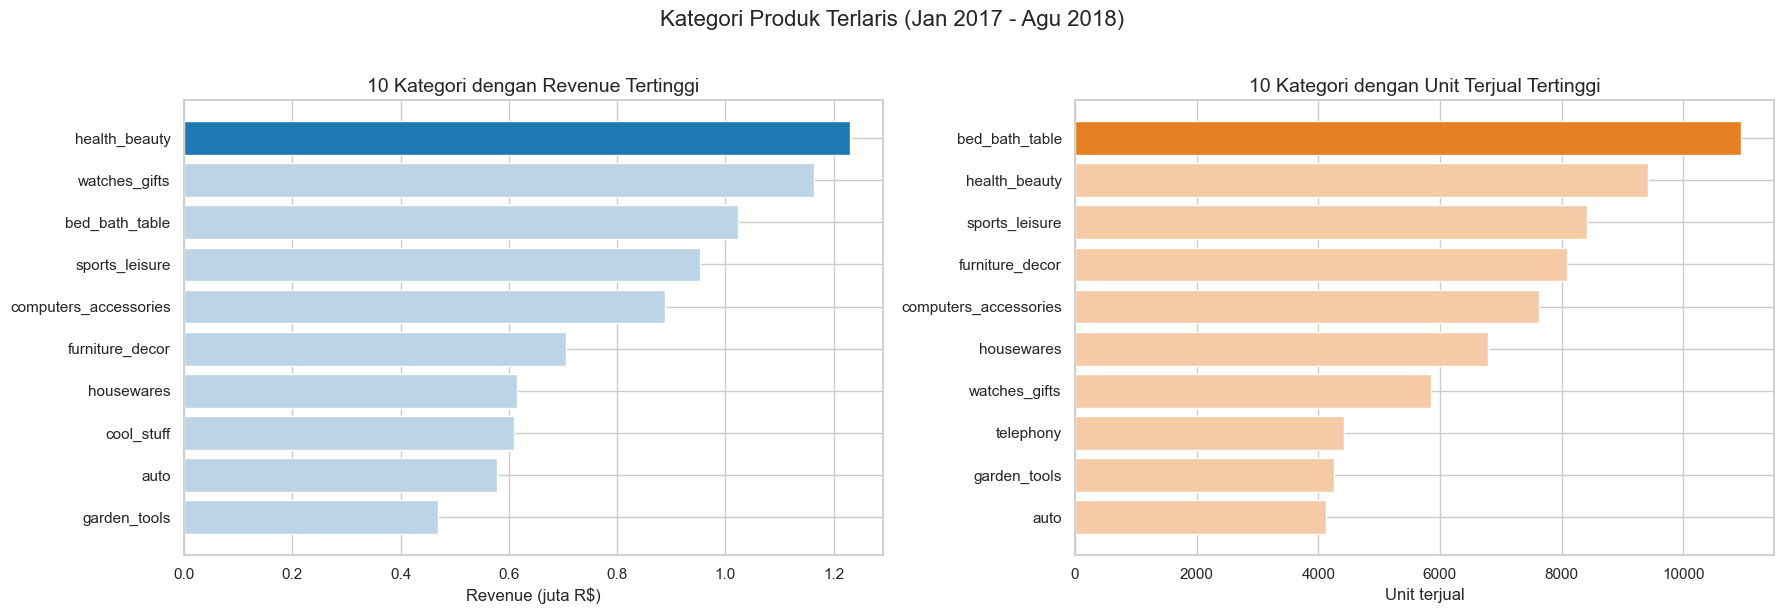

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Top 10 Revenue
top_rev = category_summary.head(10).sort_values('revenue')
colors_rev = ['#93C5FD'] * (len(top_rev) - 1) + ['#1D4ED8']
bars0 = axes[0].barh(top_rev.index, top_rev['revenue'] / 1e6, color=colors_rev, height=0.65)
axes[0].set_title('10 Kategori dengan Total Revenue Tertinggi', fontsize=14, fontweight='bold', pad=15)
axes[0].set_xlabel('Total Revenue (Juta R$)', fontsize=11, fontweight='semibold')
axes[0].bar_label(bars0, fmt='R$ %.2fM', padding=5, fontsize=10, fontweight='bold', color='#1E293B')
axes[0].set_xlim(0, (top_rev['revenue'].max() / 1e6) * 1.18)

# Top 10 Unit Terjual
top_unit = category_summary.sort_values('unit_terjual', ascending=False).head(10).sort_values('unit_terjual')
colors_unit = ['#FDE68A'] * (len(top_unit) - 1) + ['#D97706']
bars1 = axes[1].barh(top_unit.index, top_unit['unit_terjual'], color=colors_unit, height=0.65)
axes[1].set_title('10 Kategori dengan Unit Terjual Terbanyak', fontsize=14, fontweight='bold', pad=15)
axes[1].set_xlabel('Total Unit Terjual', fontsize=11, fontweight='semibold')
axes[1].bar_label(bars1, fmt='{:,.0f}', padding=5, fontsize=10, fontweight='bold', color='#1E293B')
axes[1].set_xlim(0, top_unit['unit_terjual'].max() * 1.18)

for ax in axes:
    ax.grid(axis='x', linestyle='--', alpha=0.5)
    sns.despine(ax=ax, top=True, right=True)

plt.suptitle('Perbandingan Kategori Produk Unggulan (Januari 2017 – Agustus 2018)', fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


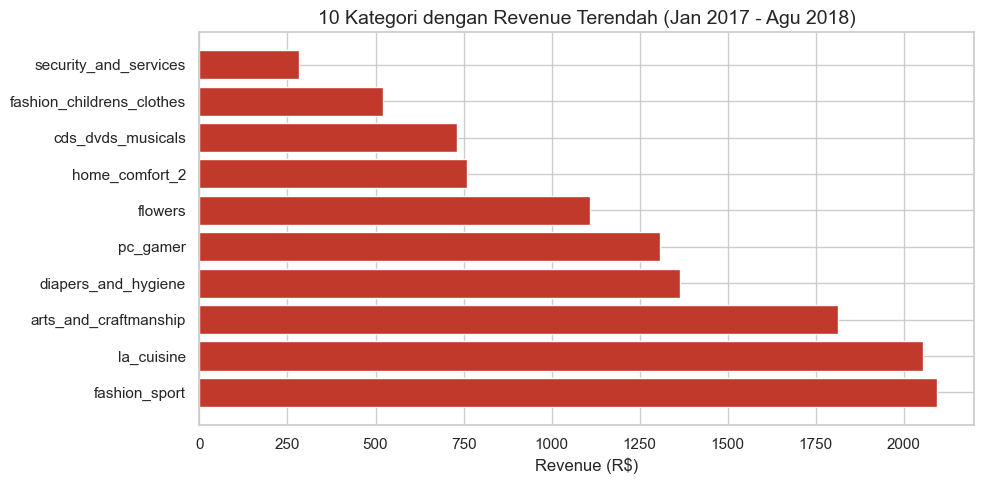

In [25]:
bottom = category_summary.sort_values('revenue').head(10)
plt.figure(figsize=(10, 5))
bars = plt.barh(bottom.index[::-1], bottom['revenue'][::-1], color='#E11D48', height=0.65)
plt.title('10 Kategori Produk dengan Revenue Terendah (Januari 2017 – Agustus 2018)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Total Revenue (R$)', fontsize=11, fontweight='semibold')
plt.bar_label(bars, fmt='R$ {:,.0f}', padding=5, fontsize=9.5, fontweight='bold', color='#1E293B')
plt.xlim(0, bottom['revenue'].max() * 1.25)
plt.grid(axis='x', linestyle='--', alpha=0.5)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()


### Pertanyaan 2: Pengaruh keterlambatan pengiriman terhadap review score

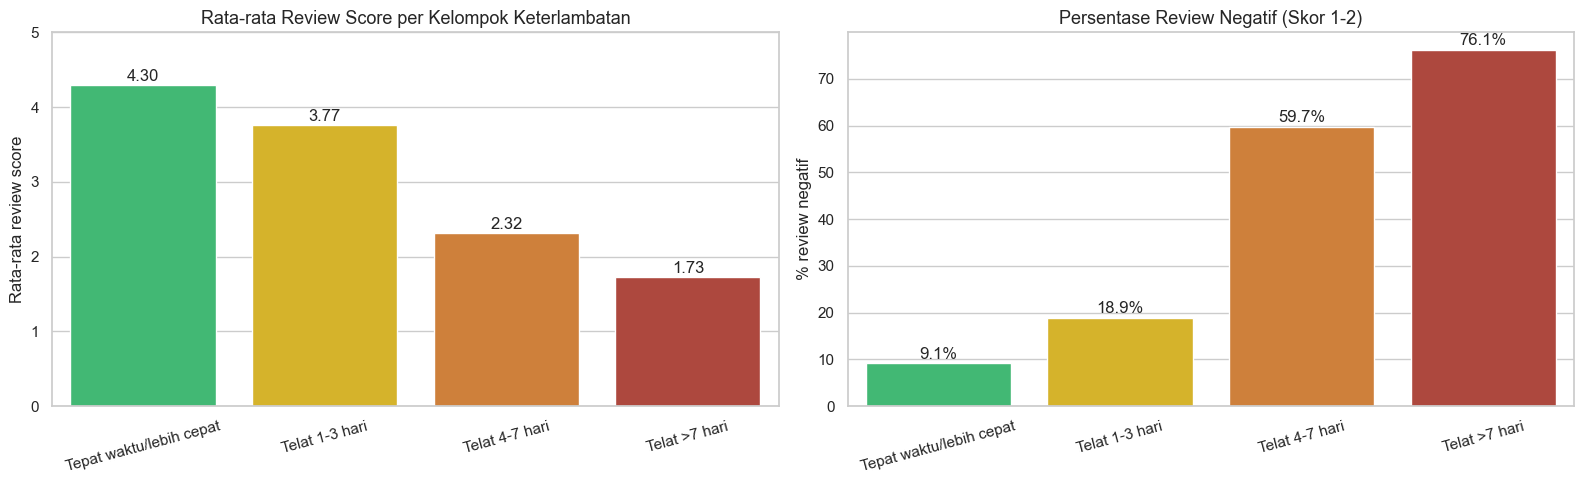

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
palette = ['#10B981', '#F59E0B', '#F97316', '#EF4444']

# Rata-rata Review Score
bars0 = axes[0].bar(delay_summary.index, delay_summary['rata_rata_review'], color=palette, width=0.55)
axes[0].set_title('Rata-rata Review Score per Kelompok Keterlambatan', fontsize=13, fontweight='bold', pad=12)
axes[0].set_ylabel('Rata-rata Skor Review (Skala 1–5)', fontsize=11, fontweight='semibold')
axes[0].set_ylim(0, 5.2)
axes[0].bar_label(bars0, fmt='%.2f', padding=4, fontsize=10, fontweight='bold', color='#1E293B')

# Persentase Review Negatif
bars1 = axes[1].bar(delay_summary.index, delay_summary['persen_review_negatif'], color=palette, width=0.55)
axes[1].set_title('Persentase Review Negatif (Skor 1–2)', fontsize=13, fontweight='bold', pad=12)
axes[1].set_ylabel('Persentase Review Negatif (%)', fontsize=11, fontweight='semibold')
axes[1].set_ylim(0, delay_summary['persen_review_negatif'].max() * 1.18)
axes[1].bar_label(bars1, fmt='%.1f%%', padding=4, fontsize=10, fontweight='bold', color='#1E293B')

for ax in axes:
    ax.tick_params(axis='x', rotation=12)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    sns.despine(ax=ax, top=True, right=True)

plt.suptitle('Dampak Keterlambatan Pengiriman terhadap Kepuasan Pelanggan', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### Pertanyaan 3: Sebaran pelanggan, revenue, dan performa pengiriman per state

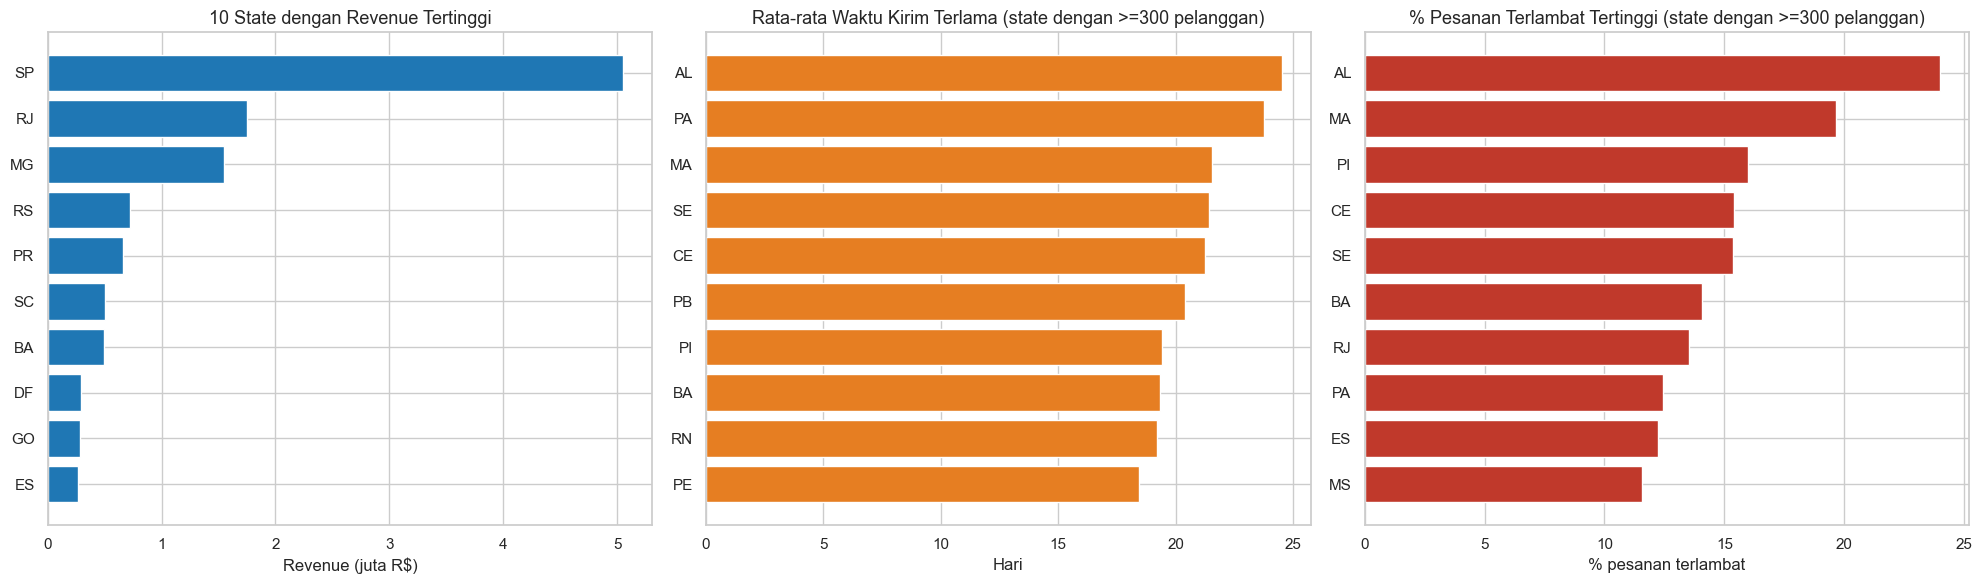

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# 1) Top 10 State Revenue
top_state = state_summary.head(10).sort_values('revenue')
colors_state = ['#93C5FD'] * (len(top_state) - 1) + ['#1D4ED8']
bars0 = axes[0].barh(top_state.index, top_state['revenue'] / 1e6, color=colors_state, height=0.65)
axes[0].set_title('10 State dengan Revenue Tertinggi', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Revenue (Juta R$)', fontsize=11, fontweight='semibold')
axes[0].bar_label(bars0, fmt='R$ %.2fM', padding=4, fontsize=9.5, fontweight='bold', color='#1E293B')
axes[0].set_xlim(0, (top_state['revenue'].max() / 1e6) * 1.18)

# 2) Durasi Pengiriman Terlama (min 300 pelanggan)
big_state = state_summary[state_summary['pelanggan'] >= 300].sort_values('rata_rata_hari_kirim', ascending=False).head(10).sort_values('rata_rata_hari_kirim')
bars1 = axes[1].barh(big_state.index, big_state['rata_rata_hari_kirim'], color='#F97316', height=0.65)
axes[1].set_title('Waktu Kirim Terlama (State ≥ 300 Pelanggan)', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Rata-rata Durasi (Hari)', fontsize=11, fontweight='semibold')
axes[1].bar_label(bars1, fmt='%.1f hari', padding=4, fontsize=9.5, fontweight='bold', color='#1E293B')
axes[1].set_xlim(0, big_state['rata_rata_hari_kirim'].max() * 1.18)

# 3) Persentase Keterlambatan Tertinggi
late_state = state_summary[state_summary['pelanggan'] >= 300].sort_values('persen_terlambat', ascending=False).head(10).sort_values('persen_terlambat')
bars2 = axes[2].barh(late_state.index, late_state['persen_terlambat'], color='#EF4444', height=0.65)
axes[2].set_title('% Keterlambatan Tertinggi (State ≥ 300 Pelanggan)', fontsize=13, fontweight='bold', pad=12)
axes[2].set_xlabel('Persentase Terlambat (%)', fontsize=11, fontweight='semibold')
axes[2].bar_label(bars2, fmt='%.1f%%', padding=4, fontsize=9.5, fontweight='bold', color='#1E293B')
axes[2].set_xlim(0, late_state['persen_terlambat'].max() * 1.2)

for ax in axes:
    ax.grid(axis='x', linestyle='--', alpha=0.5)
    sns.despine(ax=ax, top=True, right=True)

plt.suptitle('Analisis Kinerja Logistik dan Pasar Konsumen per Negara Bagian', fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


**Insight:**
- Visualisasi memperlihatkan revenue terkonsentrasi pada beberapa kategori, dan kategori dengan unit terbanyak belum tentu revenue terbesar.
- Skor review turun tajam begitu pesanan melewati estimasi tiba, sehingga ketepatan waktu menjadi faktor penting kepuasan pelanggan.
- Pasar sangat terpusat di SP, namun performa logistik terburuk ada di state yang jauh dari pusat (utara dan timur laut).

## Analisis Lanjutan (Opsional)

### RFM Analysis

Segmentasi pelanggan memakai **Recency** (hari sejak pembelian terakhir), **Frequency** (jumlah pesanan), dan **Monetary** (total belanja). Skor R dan M dibagi per kuartil (4 = terbaik).

In [28]:
customer_orders = (master_df.groupby('order_id')
                   .agg(customer_unique_id=('customer_unique_id', 'first'),
                        purchase_date=('order_purchase_timestamp', 'first'),
                        monetary=('price', 'sum'))
                   .reset_index())
ref_date = customer_orders['purchase_date'].max() + pd.Timedelta(days=1)

rfm = (customer_orders.groupby('customer_unique_id')
       .agg(recency=('purchase_date', lambda s: (ref_date - s.max()).days),
            frequency=('order_id', 'nunique'),
            monetary=('monetary', 'sum')))

rfm['r_score'] = pd.qcut(rfm['recency'], 4, labels=[4, 3, 2, 1]).astype(int)
rfm['m_score'] = pd.qcut(rfm['monetary'], 4, labels=[1, 2, 3, 4]).astype(int)

def segment(row):
    if row['frequency'] >= 2:
        return 'Repeat Buyer'
    if row['r_score'] >= 3 and row['m_score'] >= 3:
        return 'Baru - Nilai Tinggi'
    if row['r_score'] <= 2 and row['m_score'] >= 3:
        return 'Berisiko Hilang - Nilai Tinggi'
    if row['r_score'] >= 3:
        return 'Baru - Nilai Rendah'
    return 'Tidak Aktif - Nilai Rendah'

rfm['segment'] = rfm.apply(segment, axis=1)
seg_summary = (rfm.groupby('segment')
               .agg(pelanggan=('recency', 'count'), rata_recency=('recency', 'mean'), rata_monetary=('monetary', 'mean'))
               .assign(persen=lambda d: d['pelanggan'] / d['pelanggan'].sum() * 100)
               .sort_values('pelanggan', ascending=False))
seg_summary

,pelanggan,rata_recency,rata_monetary,persen
segment,,,,
Tidak Aktif - Nilai Rendah,23318,362.02,47.22,25.05
Baru - Nilai Rendah,22780,111.18,47.01,24.47
Baru - Nilai Tinggi,22244,111.80,231.57,23.89
Berisiko Hilang - Nilai Tinggi,21965,362.55,233.62,23.59
Repeat Buyer,2789,219.60,260.08,3.00


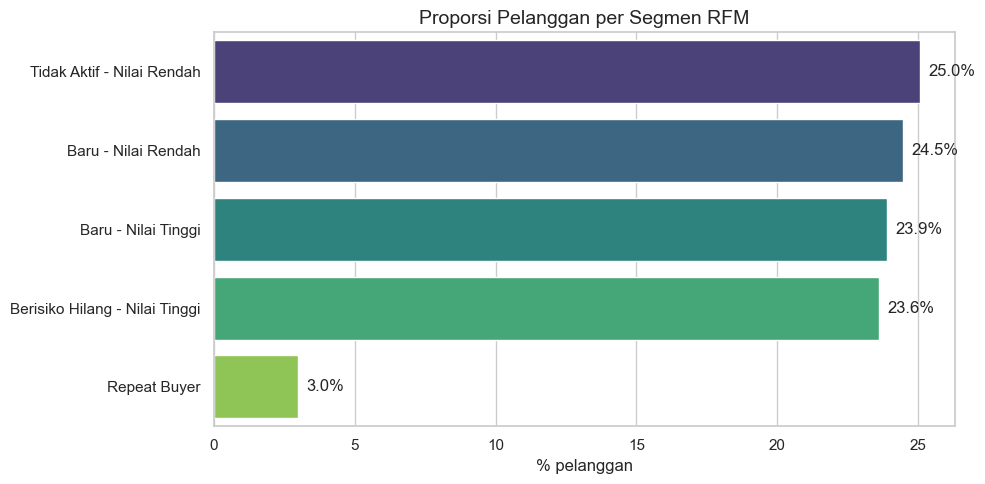

In [29]:
plt.figure(figsize=(10, 5))
palette_rfm = ['#6366F1', '#3B82F6', '#06B6D4', '#10B981', '#94A3B8']
bars = plt.barh(seg_summary.index[::-1], seg_summary['persen'][::-1], color=palette_rfm[:len(seg_summary)], height=0.65)
plt.title('Proporsi Distribusi Pelanggan per Segmen RFM', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Persentase Pelanggan (%)', fontsize=11, fontweight='semibold')
plt.ylabel('')
plt.bar_label(bars, fmt='%.1f%%', padding=5, fontsize=10, fontweight='bold', color='#1E293B')
plt.xlim(0, seg_summary['persen'].max() * 1.18)
plt.grid(axis='x', linestyle='--', alpha=0.5)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()


### Analisis Geospasial

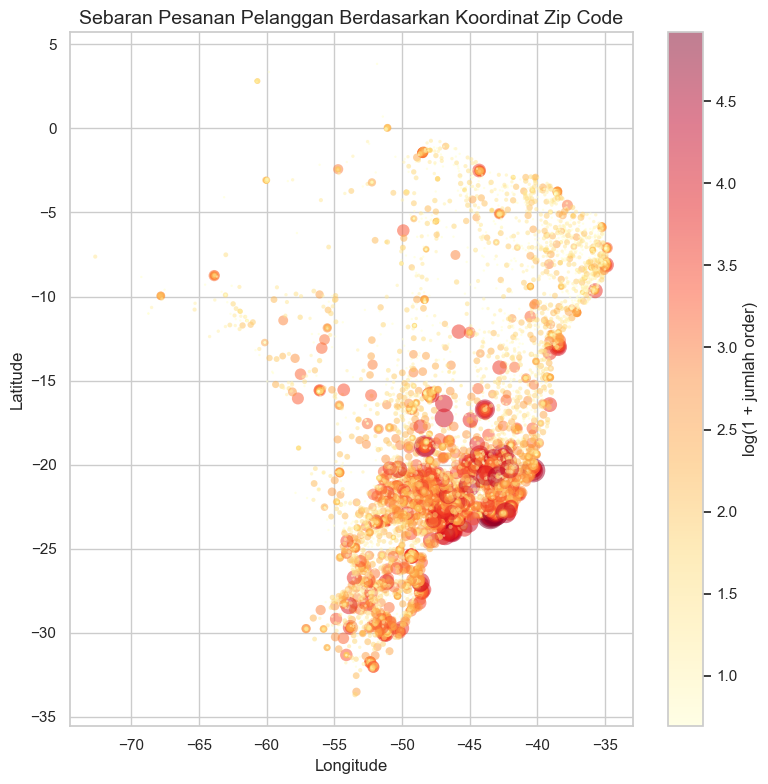

In [30]:
geo_customers = (master_df.drop_duplicates('order_id').dropna(subset=['lat', 'lng'])
                 .groupby(['customer_zip_code_prefix', 'lat', 'lng'], as_index=False)
                 .agg(jumlah_order=('order_id', 'count')))

plt.figure(figsize=(8, 8))
plt.scatter(geo_customers['lng'], geo_customers['lat'], s=geo_customers['jumlah_order'] * 3, c=np.log1p(geo_customers['jumlah_order']),
            cmap='YlOrRd', alpha=0.5, edgecolors='none')
plt.colorbar(label='log(1 + jumlah order)')
plt.title('Sebaran Pesanan Pelanggan Berdasarkan Koordinat Zip Code', fontsize=14)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.tight_layout()
plt.show()

**Insight:**
- **RFM:** hanya 3,0% pelanggan yang menjadi *repeat buyer*; sisanya hanya membeli satu kali. Sekitar 23,6% pelanggan adalah pembeli bernilai tinggi (rata-rata R$ 233) yang sudah lama tidak kembali (recency ±363 hari), sehingga ini target utama reaktivasi.
- **Geospasial:** pesanan menumpuk di tenggara Brasil (SP, RJ, MG) dan sepanjang pesisir, sedangkan wilayah utara sangat jarang.

## Menyimpan Data untuk Dashboard

In [31]:
import os
os.makedirs('dashboard', exist_ok=True)
dashboard_cols = ['order_id', 'order_item_id', 'customer_unique_id', 'customer_state', 'order_purchase_timestamp', 'category',
                  'price', 'freight_value', 'review_score', 'delivery_days', 'delay_days', 'lat', 'lng']
master_df[dashboard_cols].round(4).to_csv('dashboard/main_data.csv', index=False)
print('main_data.csv tersimpan:', master_df[dashboard_cols].shape)

main_data.csv tersimpan: (109872, 13)


## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Kategori dengan revenue tertinggi adalah `health_beauty`, `watches_gifts`, dan `bed_bath_table`; 5 kategori teratas menyumbang 39,9% revenue. Kategori `bed_bath_table` unggul di jumlah unit, sedangkan `watches_gifts` unggul karena harga tinggi. Kategori terendah (misalnya `security_and_services`, `fashion_childrens_clothes`, `cds_dvds_musicals`) hampir tidak berkontribusi.
- **Conclusion pertanyaan 2:** Pesanan terlambat hanya 8,1%, tetapi dampaknya besar: rata-rata review turun dari 4,30 menjadi 2,57 dan review negatif naik dari 9,1% menjadi 52,9%. Keterlambatan lebih dari 7 hari menghasilkan rata-rata skor 1,73 dengan 76,1% review negatif.
- **Conclusion pertanyaan 3:** SP adalah pasar utama (38,4% revenue, 41,9% pelanggan), diikuti RJ dan MG. Waktu kirim terlama ada di RR, AP, AM, dan PA (±24–30 hari), sedangkan persentase keterlambatan tertinggi di AL (24,0%), MA (19,6%), dan PI (16,0%).

**Rekomendasi Action Item:**
- Prioritaskan stok, promosi, dan bundling pada kategori revenue tertinggi (`health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, `computers_accessories`), serta evaluasi atau hentikan kategori dengan kontribusi mendekati nol.
- Perbaiki akurasi estimasi pengiriman dan tambahkan notifikasi proaktif ke pelanggan bila pesanan diperkirakan terlambat. Pesanan yang telat lebih dari 3 hari perlu ditangani khusus (kompensasi voucher atau permintaan maaf) karena review negatifnya melonjak.
- Evaluasi mitra logistik dan pertimbangkan gudang atau seller pendukung di wilayah dengan keterlambatan tinggi (AL, MA, PI, CE, RJ, BA) serta waktu kirim terlama di utara.
- Jalankan kampanye reaktivasi (voucher, email) untuk segmen *Berisiko Hilang - Nilai Tinggi* dan program loyalitas untuk mendorong pembelian ulang, karena hanya 3% pelanggan yang membeli lebih dari sekali.